In [1]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split


In [3]:
df = pd.read_csv("final_dataset.csv")
train_df, val_df = train_test_split(df, test_size=0.1, stratify=df['label'], random_state=42)

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=(224, 224),
    class_mode="categorical",
    batch_size=32
)

val_gen = datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=(224, 224),
    class_mode="categorical",
    batch_size=32,
    shuffle=False
)

num_classes = len(train_gen.class_indices)


Found 42241 validated image filenames belonging to 7 classes.
Found 4694 validated image filenames belonging to 7 classes.


In [4]:
base_model = ResNet50(include_top=False, input_shape=(224, 224, 3), weights='imagenet', pooling='avg')
base_model.trainable = False  # Freeze base initially

model = models.Sequential([
    base_model,
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,122,247 (92.02 MB)

 Trainable params: 530,439 (2.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint("resnet50_best.h5", save_best_only=True)
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9064 - loss: 0.2950

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 3777s 3s/step - accuracy: 0.9064 - loss: 0.2950 - val_accuracy: 0.9293 - val_loss: 0.2149
Epoch 2/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.9171 - loss: 0.2527

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1263s 956ms/step - accuracy: 0.9171 - loss: 0.2527 - val_accuracy: 0.9267 - val_loss: 0.2097
Epoch 3/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 866ms/step - accuracy: 0.9199 - loss: 0.2391

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1271s 962ms/step - accuracy: 0.9199 - loss: 0.2391 - val_accuracy: 0.9342 - val_loss: 0.1843
Epoch 4/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9260 - loss: 0.2197

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1575s 1s/step - accuracy: 0.9260 - loss: 0.2197 - val_accuracy: 0.9380 - val_loss: 0.1762
Epoch 5/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1264s 957ms/step - accuracy: 0.9320 - loss: 0.2028 - val_accuracy: 0.9393 - val_loss: 0.1803
Epoch 6/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1265s 957ms/step - accuracy: 0.9333 - loss: 0.1950 - val_accuracy: 0.9348 - val_loss: 0.1795
Epoch 7/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1268s 960ms/step - accuracy: 0.9341 - loss: 0.1946 - val_accuracy: 0.9323 - val_loss: 0.1801
Epoch 8/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 864ms/step - accuracy: 0.9373 - loss: 0.1811

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1282s 960ms/step - accuracy: 0.9373 - loss: 0.1811 - val_accuracy: 0.9386 - val_loss: 0.1690
Epoch 9/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1245s 943ms/step - accuracy: 0.9351 - loss: 0.1845 - val_accuracy: 0.9401 - val_loss: 0.1697
Epoch 10/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1406s 1s/step - accuracy: 0.9388 - loss: 0.1774 - val_accuracy: 0.9369 - val_loss: 0.1699
Epoch 11/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9380 - loss: 0.1716

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1628s 1s/step - accuracy: 0.9380 - loss: 0.1716 - val_accuracy: 0.9408 - val_loss: 0.1651
Epoch 12/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1582s 1s/step - accuracy: 0.9411 - loss: 0.1672 - val_accuracy: 0.9380 - val_loss: 0.1653
Epoch 13/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1530s 1s/step - accuracy: 0.9422 - loss: 0.1680 - val_accuracy: 0.9376 - val_loss: 0.1664
Epoch 14/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9462 - loss: 0.1531

1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1579s 1s/step - accuracy: 0.9462 - loss: 0.1531 - val_accuracy: 0.9399 - val_loss: 0.1628
Epoch 15/15
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 1577s 1s/step - accuracy: 0.9462 - loss: 0.1537 - val_accuracy: 0.9414 - val_loss: 0.1641


In [7]:
base_model.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 6325s 5s/step - accuracy: 0.6861 - loss: 20.7099 - val_accuracy: 0.8585 - val_loss: 5.0388
Epoch 2/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 5903s 4s/step - accuracy: 0.8999 - loss: 1.7640 - val_accuracy: 0.9056 - val_loss: 0.8163
Epoch 3/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 7287s 6s/step - accuracy: 0.9089 - loss: 0.7709 - val_accuracy: 0.9184 - val_loss: 0.5241
Epoch 4/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 6971s 5s/step - accuracy: 0.9173 - loss: 0.4757 - val_accuracy: 0.9244 - val_loss: 0.3457
Epoch 5/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 5933s 4s/step - accuracy: 0.9232 - loss: 0.3097 - val_accuracy: 0.9335 - val_loss: 0.3995
Epoch 6/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 5932s 4s/step - accuracy: 0.9290 - loss: 0.2791 - val_accuracy: 0.9342 - val_loss: 0.4052
Epoch 7/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 4726s 4s/step - accuracy: 0.9343 - loss: 0.2441 - val_accuracy: 0.9401 - val_loss: 0.2767
Epoch 8/20
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 4844s 4s/step - accuracy: 0.9335 

In [8]:
# Final evaluation
loss, acc = model.evaluate(val_gen)
print(f"✅ ResNet50 Final Validation Accuracy: {acc:.4f}")

# Save model
model.save("resnet50_skin_classifier.h5")


147/147 ━━━━━━━━━━━━━━━━━━━━ 72s 488ms/step - accuracy: 0.9477 - loss: 0.1737


✅ ResNet50 Final Validation Accuracy: 0.9491


147/147 ━━━━━━━━━━━━━━━━━━━━ 74s 493ms/step
🔍 Classification Report:
               precision    recall  f1-score   support

       AKIEC     0.9790    0.9731    0.9760       670
         BCC     0.9558    0.9672    0.9614       670
         BKL     0.9233    0.9151    0.9192       671
          DF     0.9955    0.9911    0.9933       671
         MEL     0.9589    0.8703    0.9125       671
          NV     0.8465    0.9299    0.8862       670
        VASC     0.9955    0.9970    0.9963       671

    accuracy                         0.9491      4694
   macro avg     0.9506    0.9491    0.9493      4694
weighted avg     0.9507    0.9491    0.9493      4694



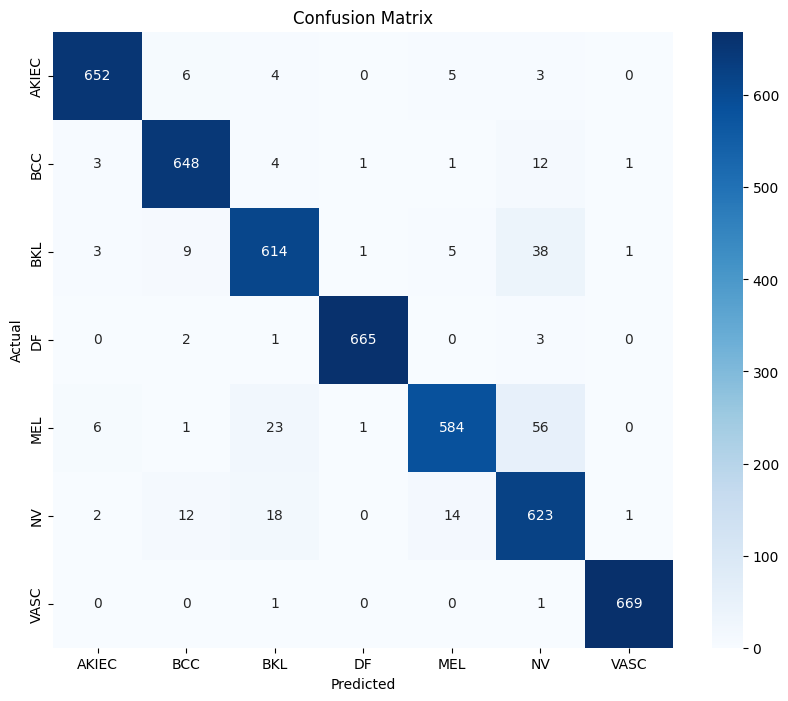

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# True labels and predicted
y_true = val_gen.classes
y_pred_probs = model.predict(val_gen)
y_pred = np.argmax(y_pred_probs, axis=1)

class_labels = list(val_gen.class_indices.keys())

# Classification report
report = classification_report(y_true, y_pred, target_names=class_labels, digits=4)
print("🔍 Classification Report:\n", report)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


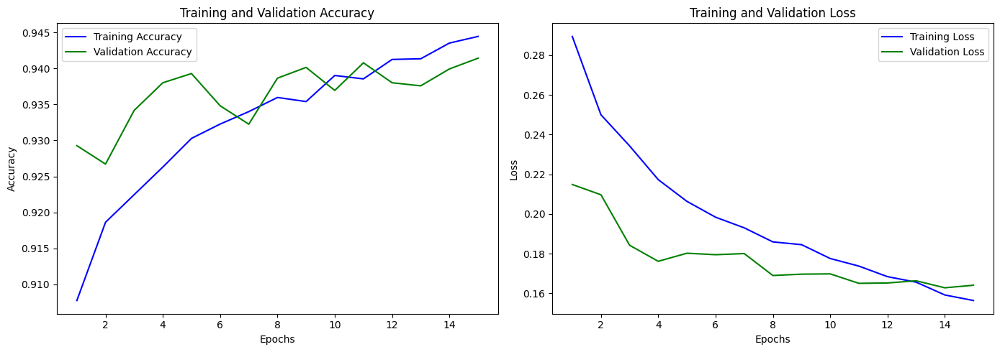

In [10]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'g-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-', label='Training Loss')
    plt.plot(epochs, val_loss, 'g-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Call it after training
plot_training_history(history)


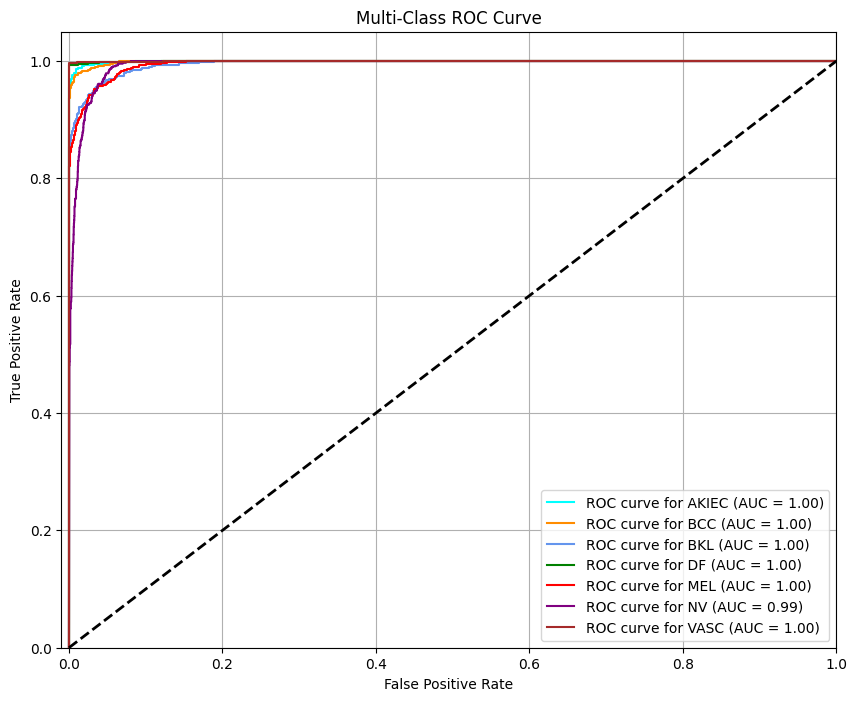

In [11]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from itertools import cycle

def plot_multiclass_roc_auc(y_true, y_pred_probs, class_labels):
    n_classes = len(class_labels)
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot all ROC curves
    plt.figure(figsize=(10, 8))
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple', 'brown'])

    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color,
                 label=f'ROC curve for {class_labels[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([-0.01, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-Class ROC Curve')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

# Call this using:
plot_multiclass_roc_auc(y_true, y_pred_probs, class_labels)


In [12]:
import os
import numpy as np
from datetime import datetime
from sklearn.metrics import classification_report, roc_auc_score
from tensorflow.keras.utils import to_categorical

def evaluate_and_log_model_plain(y_true, y_pred_probs, class_labels, model_name="MyModel", log_file="model_report.txt"):
    # Convert to class predictions
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.array(y_true)
    y_true_bin = to_categorical(y_true, num_classes=len(class_labels))

    # Get classification metrics
    report = classification_report(y_true, y_pred, target_names=class_labels, digits=4, output_dict=True)
    accuracy = report["accuracy"]
    f1 = report["weighted avg"]["f1-score"]
    precision = report["weighted avg"]["precision"]
    recall = report["weighted avg"]["recall"]
    
    # Try ROC AUC
    try:
        roc_auc = roc_auc_score(y_true_bin, y_pred_probs, average='weighted', multi_class='ovr')
        roc_auc_str = f"{roc_auc:.4f}"
    except:
        roc_auc_str = "N/A"

    # Create log string
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    log_entry = f"""
==========================
Timestamp : {timestamp}
Model     : {model_name}
Accuracy  : {accuracy:.4f}
Precision : {precision:.4f}
Recall    : {recall:.4f}
F1 Score  : {f1:.4f}
ROC AUC   : {roc_auc_str}
==========================

"""

    # Append to text file (plain encoding)
    with open(log_file, "a") as f:
        f.write(log_entry)

    print("Model evaluation logged successfully.")
    print(log_entry)


In [14]:
# After training
y_true = val_gen.classes
y_pred_probs = model.predict(val_gen)
class_labels = list(val_gen.class_indices.keys())

# Log model evaluation
evaluate_and_log_model_plain(y_true, y_pred_probs, class_labels, model_name="ResNet50")


147/147 ━━━━━━━━━━━━━━━━━━━━ 71s 483ms/step
Model evaluation logged successfully.

Timestamp : 2025-07-03 08:21:37
Model     : ResNet50
Accuracy  : 0.9491
Precision : 0.9507
Recall    : 0.9491
F1 Score  : 0.9493
ROC AUC   : 0.9973




In [15]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os


In [18]:
for i, layer in enumerate(model.layers):
    print(f"{i}: {layer.name} - {layer.__class__.__name__}")


0: resnet50 - Functional
1: batch_normalization - BatchNormalization
2: dense - Dense
3: dropout - Dropout
4: dense_1 - Dense


In [19]:
# Access the internal DenseNet121 model
base_model = model.get_layer('resnet50')

# Print layers inside DenseNet
for i, layer in enumerate(base_model.layers):
    print(i, layer.name, "-", layer.__class__.__name__)

0 input_layer - InputLayer
1 conv1_pad - ZeroPadding2D
2 conv1_conv - Conv2D
3 conv1_bn - BatchNormalization
4 conv1_relu - Activation
5 pool1_pad - ZeroPadding2D
6 pool1_pool - MaxPooling2D
7 conv2_block1_1_conv - Conv2D
8 conv2_block1_1_bn - BatchNormalization
9 conv2_block1_1_relu - Activation
10 conv2_block1_2_conv - Conv2D
11 conv2_block1_2_bn - BatchNormalization
12 conv2_block1_2_relu - Activation
13 conv2_block1_0_conv - Conv2D
14 conv2_block1_3_conv - Conv2D
15 conv2_block1_0_bn - BatchNormalization
16 conv2_block1_3_bn - BatchNormalization
17 conv2_block1_add - Add
18 conv2_block1_out - Activation
19 conv2_block2_1_conv - Conv2D
20 conv2_block2_1_bn - BatchNormalization
21 conv2_block2_1_relu - Activation
22 conv2_block2_2_conv - Conv2D
23 conv2_block2_2_bn - BatchNormalization
24 conv2_block2_2_relu - Activation
25 conv2_block2_3_conv - Conv2D
26 conv2_block2_3_bn - BatchNormalization
27 conv2_block2_add - Add
28 conv2_block2_out - Activation
29 conv2_block3_1_conv - Conv2D


In [31]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

    return heatmap.numpy()


In [40]:
print(f"Last conv layer used for Grad-CAM: {last_conv_layer_name}")
# Print inner layers of the base ResNet50 model
for i, layer in enumerate(base_model.layers):
    print(f"{i}: {layer.name} - {layer.__class__.__name__}")

Last conv layer used for Grad-CAM: conv5_block3_out
0: input_layer - InputLayer
1: conv1_pad - ZeroPadding2D
2: conv1_conv - Conv2D
3: conv1_bn - BatchNormalization
4: conv1_relu - Activation
5: pool1_pad - ZeroPadding2D
6: pool1_pool - MaxPooling2D
7: conv2_block1_1_conv - Conv2D
8: conv2_block1_1_bn - BatchNormalization
9: conv2_block1_1_relu - Activation
10: conv2_block1_2_conv - Conv2D
11: conv2_block1_2_bn - BatchNormalization
12: conv2_block1_2_relu - Activation
13: conv2_block1_0_conv - Conv2D
14: conv2_block1_3_conv - Conv2D
15: conv2_block1_0_bn - BatchNormalization
16: conv2_block1_3_bn - BatchNormalization
17: conv2_block1_add - Add
18: conv2_block1_out - Activation
19: conv2_block2_1_conv - Conv2D
20: conv2_block2_1_bn - BatchNormalization
21: conv2_block2_1_relu - Activation
22: conv2_block2_2_conv - Conv2D
23: conv2_block2_2_bn - BatchNormalization
24: conv2_block2_2_relu - Activation
25: conv2_block2_3_conv - Conv2D
26: conv2_block2_3_bn - BatchNormalization
27: conv2_bl

In [35]:
# Print all layer names and types in reverse
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        print(f"Last conv layer: {layer.name}")
        break


c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


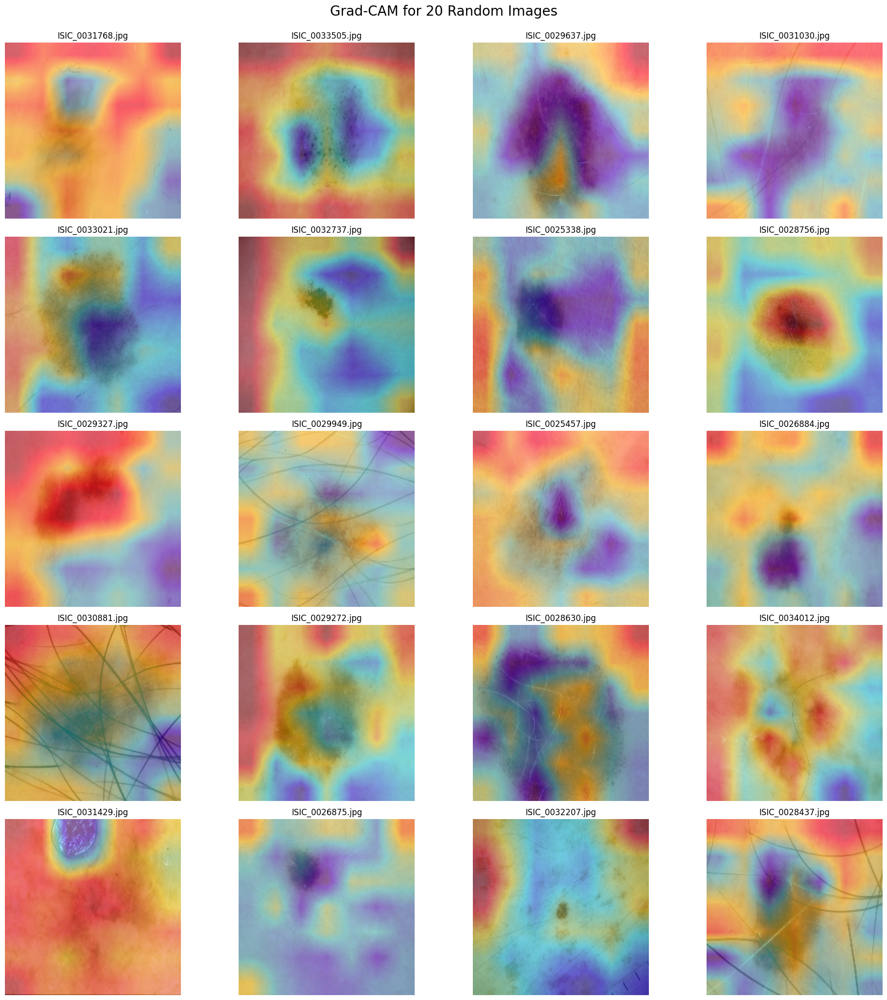

In [33]:
import os
import cv2
import random
import matplotlib.pyplot as plt

# Path to image folder
img_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"
image_files = random.sample(os.listdir(img_dir), 20)
last_conv_layer_name = "conv5_block3_out"  # ResNet50

plt.figure(figsize=(20, 20))

for i, img_name in enumerate(image_files):
    img_path = os.path.join(img_dir, img_name)

    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array_expanded = np.expand_dims(img_array, axis=0) / 255.0

    # Generate Grad-CAM
    heatmap = make_gradcam_heatmap(img_array_expanded, base_model, last_conv_layer_name)

    # Prepare for overlay
    img_orig = cv2.imread(img_path)
    img_orig = cv2.resize(img_orig, (224, 224))
    img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img_orig, 0.6, heatmap_color, 0.4, 0)

    # Plot
    plt.subplot(5, 4, i + 1)
    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.title(img_name)

plt.tight_layout()
plt.suptitle("Grad-CAM for 20 Random Images", fontsize=20, y=1.02)
plt.show()


In [41]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import tensorflow as tf
import cv2


c:\Users\devgo\OneDrive\Desktop\project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [42]:
# Define prediction wrapper for LIME
def predict_fn(images):
    images = np.array(images) / 255.0
    return model.predict(images)


In [43]:
def run_lime_on_image(img_path, model):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = img_array.astype(np.uint8)

    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        image=img_array,
        classifier_fn=predict_fn,
        top_labels=1,
        hide_color=0,
        num_samples=1000
    )

    temp, mask = explanation.get_image_and_mask(
        label=explanation.top_labels[0],
        positive_only=True,
        num_features=10,
        hide_rest=False
    )

    result = mark_boundaries(temp / 255.0, mask)
    return result


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


  1%|          | 10/1000 [00:03<05:13,  3.15it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step


  2%|▏         | 20/1000 [00:03<02:31,  6.48it/s]

...

 98%|█████████▊| 980/1000 [00:38<00:00, 24.95it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step


 99%|█████████▉| 990/1000 [00:39<00:00, 25.39it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step


100%|██████████| 1000/1000 [00:39<00:00, 25.13it/s]


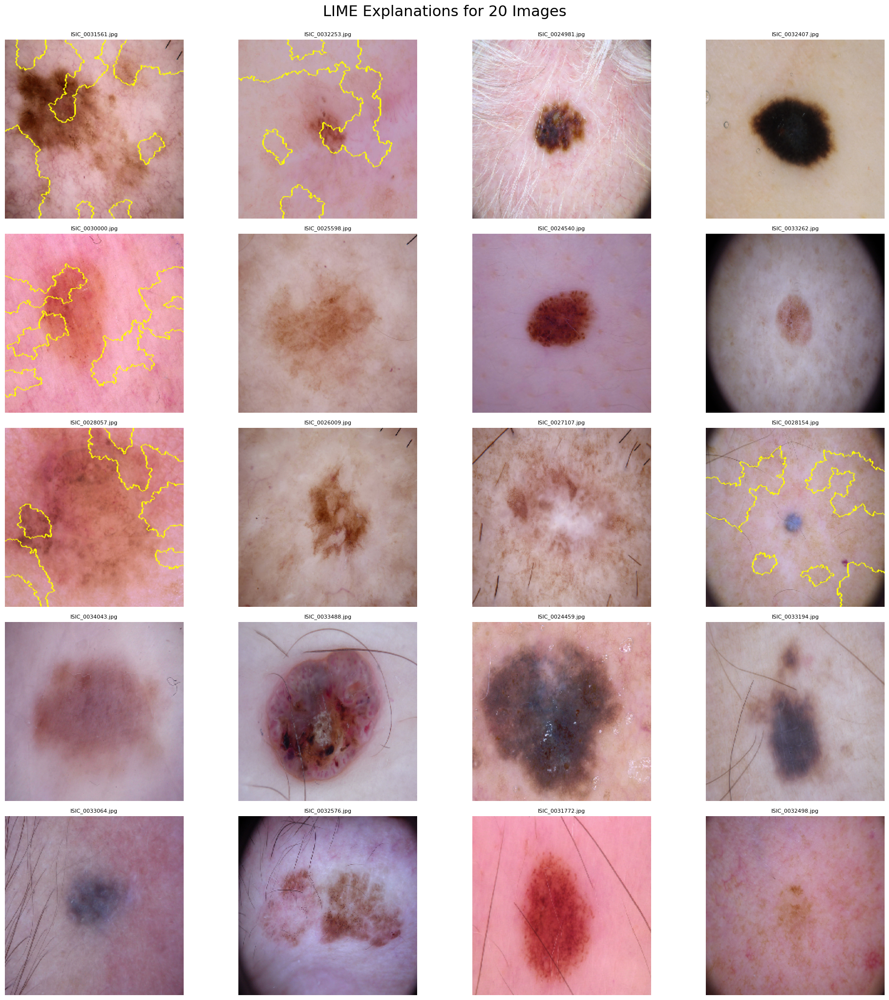

In [44]:
# Directory with your images
img_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"
image_files = random.sample(os.listdir(img_dir), 20)

plt.figure(figsize=(20, 20))

for i, img_name in enumerate(image_files):
    img_path = os.path.join(img_dir, img_name)

    try:
        result = run_lime_on_image(img_path, model)

        plt.subplot(5, 4, i + 1)
        plt.imshow(result)
        plt.title(img_name, fontsize=8)
        plt.axis("off")
    except Exception as e:
        print(f"Error processing {img_name}: {e}")

plt.tight_layout()
plt.suptitle("LIME Explanations for 20 Images", fontsize=22, y=1.02)
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step


  1%|          | 10/1000 [00:00<00:26, 37.48it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step


  2%|▏         | 20/1000 [00:00<00:24, 40.70it/s]

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step


 47%|████▋     | 470/1000 [00:11<00:12, 43.34it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step


 48%|████▊     | 479/1000 [00:11<00:12, 42.37it/s]


KeyboardInterrupt: 

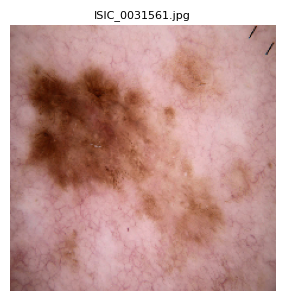

In [46]:
plt.figure(figsize=(20, 20))

for i, img_name in enumerate(image_files):
    img_path = os.path.join(img_dir, img_name)
    
    try:
        result = run_lime_on_image(img_path, model)  # Optional: if already saved, skip this line
        plt.subplot(5, 4, i + 1)
        plt.imshow(result)
        plt.title(img_name, fontsize=8)
        plt.axis("off")
    except Exception as e:
        print(f"Error displaying {img_name}: {e}")

plt.tight_layout()
plt.suptitle("Previously Generated LIME Explanations", fontsize=22, y=1.02)
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step


  1%|          | 10/1000 [00:00<01:07, 14.60it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step


  2%|▏         | 20/1000 [00:01<00:58, 16.68it/s]

...

 98%|█████████▊| 980/1000 [01:15<00:01, 18.17it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step


 99%|█████████▉| 990/1000 [01:16<00:00, 18.32it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


100%|██████████| 1000/1000 [01:16<00:00, 13.02it/s]


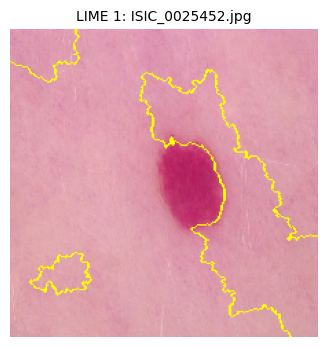

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step


  1%|          | 10/1000 [00:00<00:52, 18.71it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step


  2%|▏         | 20/1000 [00:01<00:50, 19.33it/s]

...

 98%|█████████▊| 980/1000 [01:07<00:01, 11.05it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 625ms/step


 99%|█████████▉| 990/1000 [01:08<00:00, 10.94it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 589ms/step


100%|██████████| 1000/1000 [01:09<00:00, 14.44it/s]


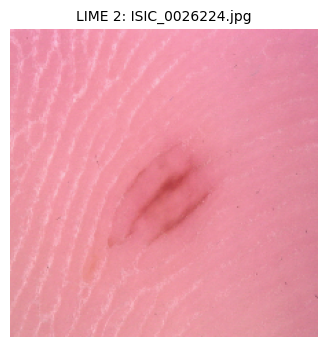

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 842ms/step


  1%|          | 10/1000 [00:01<01:42,  9.69it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 700ms/step


  2%|▏         | 20/1000 [00:01<01:32, 10.62it/s]

...

 98%|█████████▊| 980/1000 [01:29<00:01, 11.01it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 693ms/step


 99%|█████████▉| 990/1000 [01:30<00:00, 11.14it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 668ms/step


100%|██████████| 1000/1000 [01:31<00:00, 10.92it/s]


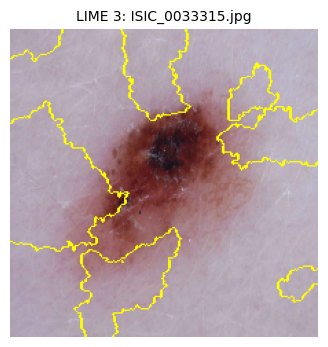

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 711ms/step


  1%|          | 10/1000 [00:01<01:44,  9.50it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 733ms/step


  2%|▏         | 20/1000 [00:01<01:33, 10.48it/s]

...

 98%|█████████▊| 980/1000 [01:23<00:01, 10.95it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 604ms/step


 99%|█████████▉| 990/1000 [01:24<00:00, 10.91it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 607ms/step


100%|██████████| 1000/1000 [01:25<00:00, 11.73it/s]


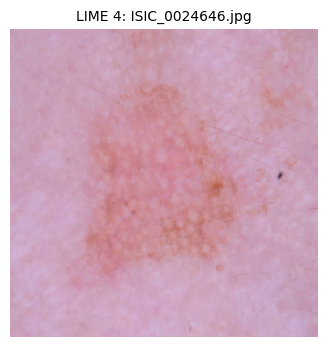

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 671ms/step


  1%|          | 10/1000 [00:00<01:32, 10.68it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 649ms/step


  2%|▏         | 20/1000 [00:01<01:29, 10.89it/s]

...

 98%|█████████▊| 980/1000 [01:29<00:01, 11.19it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step


 99%|█████████▉| 990/1000 [01:30<00:00, 11.14it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 606ms/step


100%|██████████| 1000/1000 [01:31<00:00, 10.90it/s]


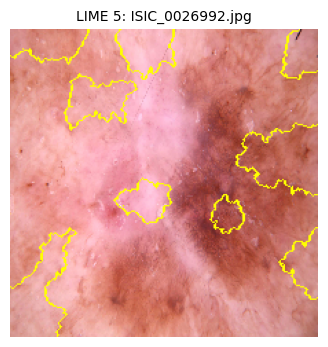

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 707ms/step


  1%|          | 10/1000 [00:00<01:30, 10.91it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 650ms/step


  2%|▏         | 20/1000 [00:01<01:30, 10.84it/s]

...

 98%|█████████▊| 980/1000 [01:17<00:01, 13.60it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 559ms/step


 99%|█████████▉| 990/1000 [01:18<00:00, 13.78it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 598ms/step


100%|██████████| 1000/1000 [01:19<00:00, 12.66it/s]


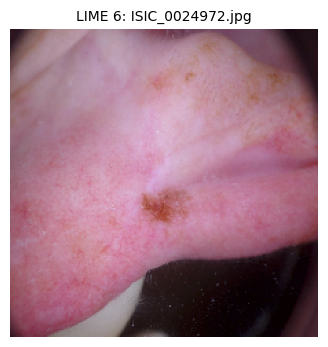

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step


  1%|          | 10/1000 [00:00<01:10, 14.06it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 564ms/step


  2%|▏         | 20/1000 [00:01<01:12, 13.47it/s]

...

 98%|█████████▊| 980/1000 [01:09<00:01, 18.78it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 570ms/step


 99%|█████████▉| 990/1000 [01:09<00:00, 16.90it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step


100%|██████████| 1000/1000 [01:10<00:00, 14.16it/s]


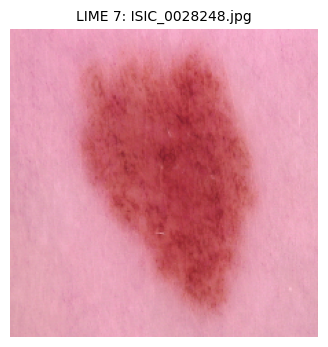

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 556ms/step


  1%|          | 10/1000 [00:00<01:09, 14.15it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 556ms/step


  2%|▏         | 20/1000 [00:01<01:14, 13.22it/s]

...

 98%|█████████▊| 980/1000 [01:10<00:01, 13.93it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 568ms/step


 99%|█████████▉| 990/1000 [01:11<00:00, 13.91it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 567ms/step


100%|██████████| 1000/1000 [01:11<00:00, 13.91it/s]


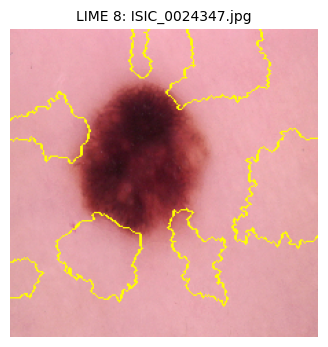

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step


  1%|          | 10/1000 [00:00<01:10, 14.05it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 578ms/step


  2%|▏         | 20/1000 [00:01<01:11, 13.79it/s]

...

 98%|█████████▊| 980/1000 [01:10<00:01, 13.72it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 548ms/step


 99%|█████████▉| 990/1000 [01:10<00:00, 13.89it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 567ms/step


100%|██████████| 1000/1000 [01:11<00:00, 14.00it/s]


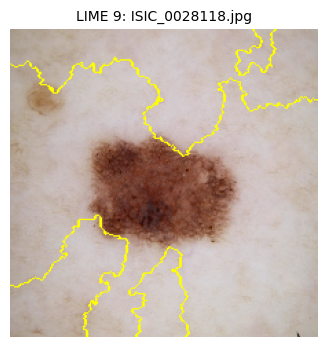

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 619ms/step


  1%|          | 10/1000 [00:00<01:22, 12.05it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 583ms/step


  2%|▏         | 20/1000 [00:01<01:19, 12.35it/s]

...

 98%|█████████▊| 980/1000 [01:10<00:01, 13.96it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 568ms/step


 99%|█████████▉| 990/1000 [01:11<00:00, 14.01it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step


100%|██████████| 1000/1000 [01:12<00:00, 13.83it/s]


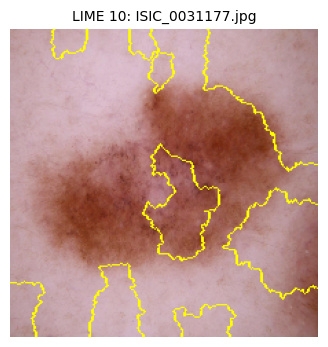

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 572ms/step


  1%|          | 10/1000 [00:00<01:10, 14.01it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step


  2%|▏         | 20/1000 [00:01<01:15, 13.04it/s]

...

 98%|█████████▊| 980/1000 [01:10<00:01, 13.94it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step


 99%|█████████▉| 990/1000 [01:11<00:00, 13.98it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 581ms/step


100%|██████████| 1000/1000 [01:12<00:00, 13.82it/s]


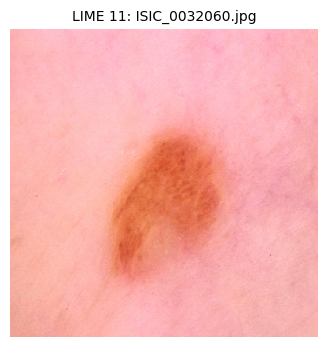

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step


  1%|          | 10/1000 [00:00<01:09, 14.25it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step


  2%|▏         | 20/1000 [00:01<01:09, 14.07it/s]

...

 98%|█████████▊| 980/1000 [01:10<00:01, 13.86it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step


 99%|█████████▉| 990/1000 [01:11<00:00, 13.82it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 570ms/step


100%|██████████| 1000/1000 [01:11<00:00, 13.89it/s]


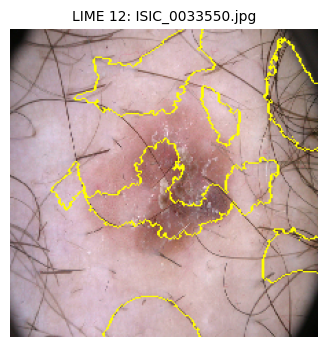

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step


  1%|          | 10/1000 [00:00<01:12, 13.63it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 605ms/step


  2%|▏         | 20/1000 [00:01<01:15, 12.94it/s]

...

 98%|█████████▊| 980/1000 [01:07<00:00, 23.25it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step


 99%|█████████▉| 990/1000 [01:07<00:00, 24.05it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step


100%|██████████| 1000/1000 [01:07<00:00, 14.72it/s]


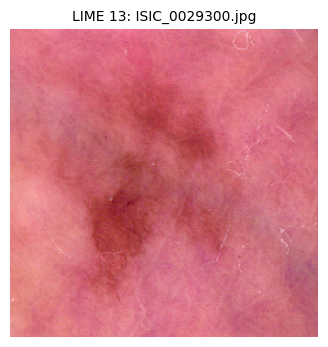

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step


  1%|          | 10/1000 [00:00<00:43, 22.97it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step


  2%|▏         | 20/1000 [00:00<00:40, 24.43it/s]

...

 98%|█████████▊| 980/1000 [00:45<00:01, 17.91it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step


 99%|█████████▉| 990/1000 [00:45<00:00, 18.15it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step


100%|██████████| 1000/1000 [00:46<00:00, 21.56it/s]


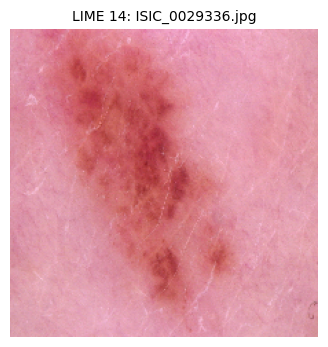

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step


  1%|          | 10/1000 [00:00<00:55, 17.72it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step


  2%|▏         | 20/1000 [00:01<00:52, 18.53it/s]

...

 98%|█████████▊| 980/1000 [01:15<00:01, 10.77it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 603ms/step


 99%|█████████▉| 990/1000 [01:16<00:00, 10.75it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 636ms/step


100%|██████████| 1000/1000 [01:17<00:00, 12.98it/s]


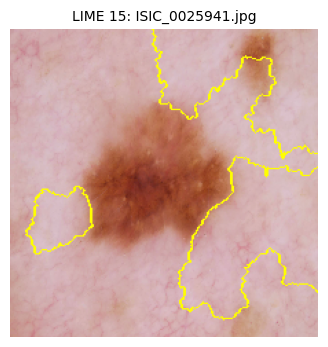

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 733ms/step


  1%|          | 10/1000 [00:00<01:35, 10.41it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 609ms/step


  2%|▏         | 20/1000 [00:01<01:32, 10.64it/s]

...

 98%|█████████▊| 980/1000 [01:25<00:01, 11.49it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 668ms/step


 99%|█████████▉| 990/1000 [01:26<00:00, 11.63it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step


100%|██████████| 1000/1000 [01:27<00:00, 11.47it/s]


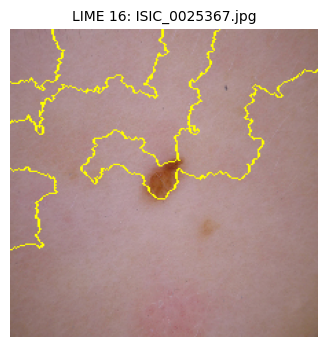

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 794ms/step


  1%|          | 10/1000 [00:00<01:37, 10.18it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 677ms/step


  2%|▏         | 20/1000 [00:01<01:31, 10.76it/s]

...

 99%|█████████▉| 989/1000 [01:36<00:00, 14.39it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step


 99%|█████████▉| 993/1000 [01:37<00:00, 10.77it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 614ms/step


100%|██████████| 1000/1000 [01:38<00:00, 10.20it/s]


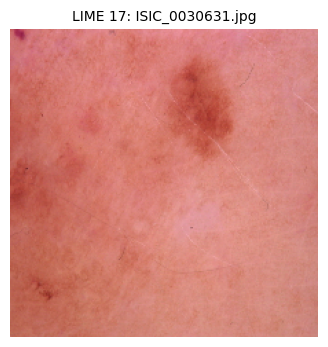

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 660ms/step


  1%|          | 10/1000 [00:00<01:22, 12.06it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step


  2%|▏         | 20/1000 [00:01<01:17, 12.61it/s]

...

 98%|█████████▊| 980/1000 [01:30<00:01, 10.45it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 627ms/step


 99%|█████████▉| 990/1000 [01:30<00:00, 10.45it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 644ms/step


100%|██████████| 1000/1000 [01:31<00:00, 10.88it/s]


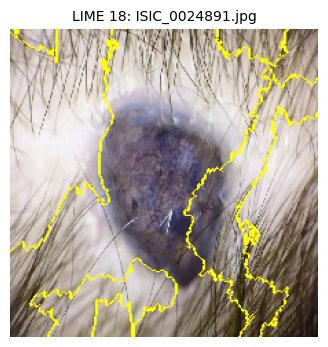

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step


  1%|          | 10/1000 [00:00<01:29, 11.01it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step


  3%|▎         | 29/1000 [00:01<00:54, 17.93it/s]

...

 98%|█████████▊| 980/1000 [01:30<00:01, 10.84it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 751ms/step


 99%|█████████▉| 990/1000 [01:31<00:00, 10.91it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 696ms/step


100%|██████████| 1000/1000 [01:32<00:00, 10.84it/s]


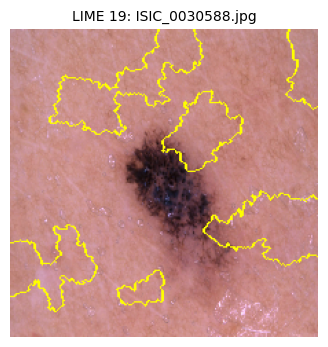

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 647ms/step


  1%|          | 10/1000 [00:00<01:37, 10.14it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 583ms/step


  2%|▏         | 20/1000 [00:01<01:30, 10.79it/s]

...

 98%|█████████▊| 980/1000 [01:29<00:01, 10.80it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step


 99%|█████████▉| 990/1000 [01:30<00:00, 10.68it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 624ms/step


100%|██████████| 1000/1000 [01:31<00:00, 10.91it/s]


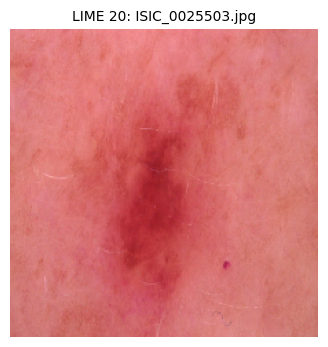

In [57]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import tensorflow as tf

# 🔧 STEP 1: Set model name (this determines output folder)
model_name = "ResNet50"  # Change this per model (e.g. CNN, ResNet50, DenseNet)

# 🔧 STEP 2: Define prediction function (ensure normalization)
def predict_fn(images):
    images = np.array(images) / 255.0  # Normalization to match training
    return model.predict(images)

# ✅ STEP 3: Function to generate LIME result (compatible version)
def lime_result_only(img_path):
    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img).astype(np.uint8)

    # Initialize LIME explainer
    explainer = lime_image.LimeImageExplainer()

    # Generate explanation
    explanation = explainer.explain_instance(
        image=img_array,
        classifier_fn=predict_fn,
        top_labels=1,
        num_samples=1000
    )

    # Get mask and visualized result (NOTE: no 'hide_color' used here)
    result, mask = explanation.get_image_and_mask(
        label=explanation.top_labels[0],
        positive_only=True,
        num_features=10,
        hide_rest=False
    )

    # Return final image with highlighted superpixels
    return mark_boundaries(result / 255.0, mask)

# 📂 STEP 4: Setup image directory
img_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"

# 📂 STEP 5: Create output folder
output_dir = f"lime_outputs/{model_name}"
os.makedirs(output_dir, exist_ok=True)

# 🔄 STEP 6: Run LIME on 20 random images
image_files = random.sample(os.listdir(img_dir), 20)

for i, img_name in enumerate(image_files):
    try:
        img_path = os.path.join(img_dir, img_name)
        result_img = lime_result_only(img_path)

        # Save LIME result
        save_path = os.path.join(output_dir, f"lime_{i+1:02d}_{img_name}")
        plt.imsave(save_path, result_img)

        # Display result
        plt.figure(figsize=(4, 4))
        plt.imshow(result_img)
        plt.title(f"LIME {i+1}: {img_name}", fontsize=10)
        plt.axis("off")
        plt.show()

    except Exception as e:
        print(f"❌ Error processing {img_name}: {e}")
